# 1mm XYZ Sampler

In [55]:
# import system libraries
import logging
import sys, copy
# import scientific libraries
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.interpolate import InterpolatedUnivariateSpline as spline
import h5py
import pandas as pd
# import data analysis libraries
from ldc.waveform.lisabeta import FastBHB
import lisabeta.lisa.lisa as lisa

from ldc.lisa.noise import AnalyticNoise, get_noise_model
from chainconsumer import Chain, ChainConsumer, make_sample, Truth
import lisaconstants
# import sampler libraries
from eryn.ensemble import EnsembleSampler
from eryn.state import State
from eryn.prior import uniform_dist, ProbDistContainer

from lisabeta.lisa.lisa import EvaluateTDIFreqseries
import lisabeta.tools.pyspline as pyspline
import lisabeta.lisa.lisatools as lisatools
import lisabeta.tools.pytools as pytools
from ldc.common import tools
from ldc.waveform.waveform import HpHc
import scipy.signal

#imports all dependencies and homebrewed functions
import LISA_TTL_Functions as foc

In [56]:
save_name = 'XYZ_Original_source_1mm_fix'

In [ ]:
'''
filename = '/Users/corinnekomlodi/Desktop/LDC2_sangria_training_v2.h5'
catpath = 'sky/mbhb/cat'
pMBHB_ldc = foc.sangria_source(filename, catpath, 2)
print(pMBHB_ldc)
pMBHB_ldc['Distance'] = pMBHB_ldc['Distance']*10
#pMBHB_ldc['Distance'] = 2500
print(pMBHB_ldc)
'''
day_sec = 86400
#set up the injection
#'''
pMBHB_ldc = {'EclipticLatitude': -0.30300442294174235,
 'EclipticLongitude': 1.2925183861048521,
 'PolarAngleOfSpin1': 1.2031361791056812,
 'PolarAngleOfSpin2': 2.097303543065685,
 'Spin1': 0.747377,
 'Spin2': 0.8388,
 'Mass1': 1323277.47932,
 'Mass2': 612485.5060299999,
 'CoalescenceTime': 5*day_sec,
 'PhaseAtCoalescence': 1.2201968860015653,
 'InitialPolarAngleL': 2.6919824500032945,
 'InitialAzimuthalAngleL': 1.808398497592109,
 'Redshift': 1.73941,
 'Distance': 13470.983559,
 'ObservationDuration': 31558149.763545603,
 'Cadence': 3.0}
 #'''

In [58]:
#establish t_min, max, separation and number of samples
t_min = 0
t_max = pMBHB_ldc["CoalescenceTime"]+day_sec
dt = 1/4
df = 1/t_max

t = np.arange(t_min, t_max, dt)

#set up the injection in lisabeta terms, not sure these time parameters do anything
FBH = FastBHB("MBHB", T=t_max, delta_t=dt, approx="IMRPhenomHM")
pMBHB = FBH.rename_as_lisabeta(pMBHB_ldc)

pMBHB['psi'] += np.pi
pMBHB['phi'] -= np.pi
#print(pMBHB)

In [59]:
def invNpsd(XX, XY): #This changes if arm lengths are non equa
    diagonalNpsd = (XX+XY)/(XX**2+XX*XY-2*XY**2)
    offdiagNpsd = -XY/(XX**2+XX*XY-2*XY**2)
    return diagonalNpsd, offdiagNpsd

def AETtoXYZ(A, E, T):
    X = (1/6)*(-3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    Y = (1/3)*(-np.sqrt(6)*E + np.sqrt(3)*T)
    Z = (1/6)*(3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    return X, Y, Z

# Generate 1mm/rad noise

In [60]:
#%% First Simulation(That we can alter as needed)
from lisainstrument import Instrument#, SchedulerConfigParallel#, sim_result_file
from pytdi import Data
from pytdi.michelson import X2, Y2, Z2

from ldc.lisa.noise import get_noise_model
from ldc.waveform.waveform import HpHc

#Create an orbits file for equal arm length
from lisaorbits import EqualArmlengthOrbits
#from lisaconstants import MOSAS
#from lisaconstants.indexing import MOSAS
from lisaorbits import KeplerianOrbits
from scipy.signal import welch


#from lolipops.io import Sampling, TimeSeriesArray
#from lolipops.pipelines.utils import welch

logging.basicConfig(level=logging.INFO)

# Coefficients

In [61]:
ttl_coeff_rand = 0.001*24#np.random.normal(0.001, 0.0002) #1 m/rad


ttl_coeffs = {
    # Eta RX
    "c_12_eta_rx": ttl_coeff_rand, #-0.00367766119873637,
    "c_13_eta_rx": 0.0, #-0.00306613516145773,
    "c_23_eta_rx": 0.0, #0.00406379191860704,
    "c_21_eta_rx": 0.0, #-0.00292577723420689,
    "c_31_eta_rx": 0.0, #0.00277194967621456,
    "c_32_eta_rx": 0.0, #-0.00369869832586783,
    # Phi RX
    "c_12_phi_rx": 0.0, #0.003778351983793,
    "c_13_phi_rx": 0.0, #0.00487385712667897,
    "c_23_phi_rx": 0.0, #0.00174769874388112,
    "c_21_phi_rx": 0.0, #-0.0019304854228092,
    "c_31_phi_rx": 0.0, #0.00357002815056497,
    "c_32_phi_rx": 0.0, #-0.00417893210240183,
    # Eta TX
    "c_12_eta_tx": 0.0, #0.00355682294436776,
    "c_13_eta_tx": 0.0, #0.0016380939705419,
    "c_23_eta_tx": 0.0, #-0.00117220980099441,
    "c_21_eta_tx": 0.0, #-0.00378694920673023,
    "c_31_eta_tx": 0.0, #0.00293420598270193,
    "c_32_eta_tx": 0.0, #-0.00466642014132255,
    # Phi TX
    "c_12_phi_tx": 0.0, #-0.00192846568588467,
    "c_13_phi_tx": 0.0, #0.00450805872044492,
    "c_23_phi_tx": 0.0, #-0.00468215111842327,
    "c_21_phi_tx": 0.0, #0.00429255732469105,
    "c_31_phi_tx": 0.0, #-0.00219602856834339,
    "c_32_phi_tx": 0.0, #-0.00107552757674203,
}

#set up for instrument file, ttl_coeffs is a function in simulation.ipynb that accounts for time varying coeffs, input is "c_ij_k_lx"
lisainstrument_ttl_coeffs = [
    # Local phis
    {
        "12": ttl_coeffs["c_12_phi_rx"],#ttl_coeffs[],
        "23": ttl_coeffs["c_23_phi_rx"],#ttl_coeffs[],
        "31": ttl_coeffs["c_31_phi_rx"],#ttl_coeffs[],
        "13": ttl_coeffs["c_13_phi_rx"],#ttl_coeffs[],
        "32": ttl_coeffs["c_32_phi_rx"],#ttl_coeffs[],
        "21": ttl_coeffs["c_21_phi_rx"],#ttl_coeffs[],
    },
    # Distant phis
    {
        "12": ttl_coeffs["c_12_phi_tx"],#ttl_coeffs[],
        "23": ttl_coeffs["c_23_phi_tx"],#ttl_coeffs[],
        "31": ttl_coeffs["c_31_phi_tx"],#ttl_coeffs[],
        "13": ttl_coeffs["c_13_phi_tx"],#ttl_coeffs[],
        "32": ttl_coeffs["c_32_phi_tx"],#ttl_coeffs[],
        "21": ttl_coeffs["c_21_phi_tx"],#ttl_coeffs[],
    },
    # Local etas
    {
        "12": ttl_coeffs["c_12_eta_rx"],#ttl_coeffs[],
        "23": ttl_coeffs["c_23_eta_rx"],#ttl_coeffs[],
        "31": ttl_coeffs["c_31_eta_rx"],#ttl_coeffs[],
        "13": ttl_coeffs["c_13_eta_rx"],#ttl_coeffs[],
        "32": ttl_coeffs["c_32_eta_rx"],#ttl_coeffs[],
        "21": ttl_coeffs["c_21_eta_rx"],#ttl_coeffs[],
    },
    # Distant etas
    {
        "12": ttl_coeffs["c_12_eta_tx"],#ttl_coeffs[],
        "23": ttl_coeffs["c_23_eta_tx"],#ttl_coeffs[],
        "31": ttl_coeffs["c_31_eta_tx"],#ttl_coeffs[],
        "13": ttl_coeffs["c_13_eta_tx"],#ttl_coeffs[],
        "32": ttl_coeffs["c_32_eta_tx"],#ttl_coeffs[],
        "21": ttl_coeffs["c_21_eta_tx"],#ttl_coeffs[],
    },
]

# Simulation

In [62]:
sim_name = 'TTL_only_sim_1mm.h5'

instru_t0 = 0.0  # s
instru_fs = 4  # Hz
instru_dt = 1 / instru_fs  # s also
instru_duration = pMBHB_ldc['CoalescenceTime'] + day_sec   # s
instru_size = int(instru_duration * instru_fs)  # samples
instru = Instrument(size = instru_size,
                    dt = instru_dt,
                    #orbits = 'orbits.h5', 
                    ttl_coeffs = lisainstrument_ttl_coeffs, #'random',
                    seed = 2030,
                    #sc_angular_jitter_asds=(2.5e-9, 2.5e-9, 2.5e-9), 
                    mosa_angular_jitter_asds=(2.0e-9, 1.0e-9), #[yaw, pitch] 
                    #dws_asds=1.7e-8 / 335,
                    ) 
instru.disable_all_noises(excluding = ['angular-jitters'])#, 'longitudinal-jitters'])

instru.simulate()

instru.write(sim_name, mode='w')

INFO:lisainstrument.instrument:Initializing instrumental simulation
INFO:lisainstrument.instrument:Computing measurement time vector (size=2073600, dt=0.25)
INFO:lisainstrument.instrument:Computing physics time vector (size=8294400, dt=0.0625)
INFO:lisainstrument.instrument:Computing telemetry time vector (size=7, dt=86400.0)
INFO:lisainstrument.instrument:Using default set of static proper pseudo-ranges
INFO:lisainstrument.instrument:Using pre-defined locking configuration 'N1-12'
INFO:lisainstrument.instrument:Designing antialiasing filter ('kaiser', 240, 1.1, 2.9)
INFO:lisainstrument.instrument:Starting simulation
INFO:lisainstrument.instrument:Generating clock noise
INFO:lisainstrument.instrument:Generating modulation noise
INFO:lisainstrument.instrument:Generating backlink noise
INFO:lisainstrument.instrument:Generating test-mass acceleration noise
INFO:lisainstrument.instrument:Generating ranging noise
INFO:lisainstrument.instrument:Generating OMS noise
INFO:lisainstrument.instru

In [63]:
#Build XYZ TDI channels
simdata = Data.from_instrument(sim_name)

X = X2.build(**simdata.args)(simdata.measurements) / instru.central_freq
Y = Y2.build(**simdata.args)(simdata.measurements) / instru.central_freq
Z = Z2.build(**simdata.args)(simdata.measurements) / instru.central_freq

central_freq = instru.central_freq



INFO:pytdi.interface:Loading measurement file 'TTL_only_sim_1mm.h5'


INFO:pytdi.interface:Initializing data object
INFO:pytdi.interface:Computing delay derivatives
INFO:pytdi.core:Building combination '<pytdi.core.LISATDICombination object at 0x11a5a7150>'
INFO:pytdi.core:Evaluate combination '<pytdi.core.LISATDICombination object at 0x11a5a7150>'
INFO:pytdi.core:Building combination '<pytdi.core.LISATDICombination object at 0x11a512590>'
INFO:pytdi.core:Evaluate combination '<pytdi.core.LISATDICombination object at 0x11a512590>'
INFO:pytdi.core:Building combination '<pytdi.core.LISATDICombination object at 0x11a510510>'
INFO:pytdi.core:Evaluate combination '<pytdi.core.LISATDICombination object at 0x11a510510>'


In [64]:
skip = 3000
fvec_sim = np.fft.rfftfreq(len(X[skip:]), instru_dt)
fvec = fvec_sim

In [65]:
del instru, simdata

# Generate Data

In [66]:
#Waveform Parameters
waveform_params_smbh = {
    "minf": 1e-5,
    "maxf": 1,
    "t0": 0.0,
    "timetomerger_max": 1.0,
    "tmax": 1.0,
    "TDI": "TDI2AET",
    "LISAconst": "Proposal",
    "responseapprox": "full",
    "frozenLISA": False,
    "TDIrescaled": False,
    "modes": None,
    # Waveform approximant and set of harmonics to use 
    "approximant": "IMRPhenomHM"
}

[(2, 2), (2, 1), (3, 3), (3, 2), (4, 4), (4, 3)]


/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


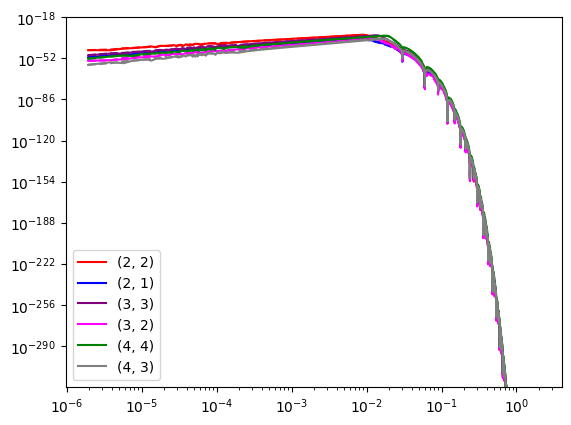

In [67]:
#Generate Data
tdisignal = lisa.GenerateLISATDISignal_SMBH(pMBHB, 
                                            gridfreq = fvec,
                                            scale_freq_hm = False,
                                            **waveform_params_smbh)
tdi = tdisignal['tdi']

modesf  = tdisignal['tdi']['modes']
colors = ['red', 'blue', 'purple', 'magenta', 'green', 'gray']
print(modesf)
A_full = np.zeros(len(fvec), dtype=complex)
E_full = np.zeros(len(fvec), dtype=complex)
T_full = np.zeros(len(fvec), dtype=complex)

for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]
        
        #phase
        splPh = mbh_lb['phase']
        #A
        splAr = mbh_lb['amp_real_chan1']
        splAi = mbh_lb['amp_imag_chan1']

        #E
        splEr = mbh_lb['amp_real_chan2']
        splEi = mbh_lb['amp_imag_chan2']

        #T
        splTr = mbh_lb['amp_real_chan3']
        splTi = mbh_lb['amp_imag_chan3']

        A_partial = np.conjugate((splAr + 1.j*splAi) * np.exp(1j*splPh))
        E_partial = np.conjugate((splEr + 1.j*splEi) * np.exp(1j*splPh))
        T_partial = np.conjugate((splTr + 1.j*splTi) * np.exp(1j*splPh))

        plt.loglog(fvec, np.abs(A_partial)**2, label = str(modesf[i]), color = colors[i])
        plt.loglog(fvec, np.abs(E_partial)**2, '--', color = colors[i])
        plt.legend()

        A_full += A_partial
        E_full += E_partial
        T_full += T_partial
    

In [68]:
DA = A_full.copy()
DE = E_full.copy()
DT = T_full.copy()

dX, dY, dZ = AETtoXYZ(DA, DE, DT)

In [69]:
#ifft then fft for windowing?
dX[0] = 0
dY[0] = 0
dZ[0] = 0
dX_ifft = np.fft.irfft(dX)/instru_dt
dY_ifft = np.fft.irfft(dY)/instru_dt
dZ_ifft = np.fft.irfft(dZ)/instru_dt

print(len(dX_ifft))

2070600


In [70]:
from scipy import signal
window = signal.windows.tukey(len(X[skip:]), alpha = 0.2)

X_t = window*(dX_ifft + X[skip:])
Y_t = window*(dY_ifft + Y[skip:])
Z_t = window*(dZ_ifft + Z[skip:])

#fft waveform +noise window
psd_X2 = np.fft.rfft(X_t)*instru_dt  # dt scaling to match waveform units
psd_Y2 = np.fft.rfft(Y_t)*instru_dt
psd_Z2 = np.fft.rfft(Z_t)*instru_dt
fvec_sim = np.fft.rfftfreq(len(X_t), instru_dt)


In [71]:
'''
TTL_only_freq = np.fft.rfft(window*X[skip:])*instru_dt
waveform_only_freq = np.fft.rfft(window*dX_ifft)*instru_dt
TTL_only_time = window*X[skip:]
waveform_only_time = window*dX_ifft
'''


'\nTTL_only_freq = np.fft.rfft(window*X[skip:])*instru_dt\nwaveform_only_freq = np.fft.rfft(window*dX_ifft)*instru_dt\nTTL_only_time = window*X[skip:]\nwaveform_only_time = window*dX_ifft\n'

In [72]:
'''
snr_cum = np.cumsum(abs(dX[2:]/Npsd_X)**2)
plt.plot(fvec_sim[1:], snr_cum)
print(snr_cum)
#plt.xlim([.005, 2e-2])
plt.hlines(1, 10e-5, 1)
plt.vlines(2e-2, 0, 1e54)
plt.vlines(1e-4, 0, 1e54)
print(fvec)
plt.xscale('log')
'''
snr_mask = np.where((fvec > 1e-4) & (fvec < 2e-2))
print(snr_mask)
print(len(snr_mask))

(array([   52,    53,    54, ..., 10350, 10351, 10352], shape=(10301,)),)
1


In [73]:
#generate noise for likelihood
#define Noises needed to calculate XYZ relations and noises 
Nmodel = AnalyticNoise(fvec, model="SciRDv1")
Npsd_X = Nmodel.psd(option='X', tdi2=True)
Npsd_XY = Nmodel.psd(option='XY', tdi2=True)
diagn, offdiagn = invNpsd(Npsd_X, Npsd_XY)

/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/ldc/lisa/noise/noise.py:302: RuntimeWarning: divide by zero encountered in divide
  sa_a = AnalyticNoise.psd_a_a[self.model] * (1.0 +(0.4e-3/frq)**2) *\
/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/ldc/lisa/noise/noise.py:304: RuntimeWarning: divide by zero encountered in power
  self.sa_d = sa_a*(2.*np.pi*frq)**(-4.) # in displacement
/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/ldc/lisa/noise/noise.py:305: RuntimeWarning: invalid value encountered in multiply
  sa_nu = self.sa_d*(2.0*np.pi*frq/CLIGHT)**2 # in rel freq unit
/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/ldc/lisa/noise/noise.py:309: RuntimeWarning: divide by zero encountered in divide
  relax = (1. + (2.e-3/frq)**4) if self.oms_relaxation else 1.0
/Users/corinnekomlodi/Desktop/Robbie_UV/.venv/lib/python3.11/site-packages/ldc/lisa/noise/noise.py:311: RuntimeWa

In [74]:
#mask -- in this one psd_X2 etc are rfft(w(irfft h + n))
DX = psd_X2[snr_mask]
DY = psd_Y2[snr_mask]
DZ = psd_Z2[snr_mask]

fvec = fvec_sim[snr_mask]

diagn = diagn[snr_mask]
offdiagn = offdiagn[snr_mask]

# Set up MCMC

In [75]:
#now we set things up for mcmc
#solving for chirpmass and ratio
m1 = pMBHB['m1']
m2 = pMBHB['m2']
q = m1/m2
Mc = (m1+m2)*(q/(1+q)**2)**0.6

src0 = pMBHB.copy()
src0["Mchirp"] = Mc
src0["q"] = q
del src0["m1"]
del src0["m2"]

keys = src0.keys()

#Fix the things that rely on pi
#src0['phi'] = np.mod(src0['phi'], np.pi)
#src0['psi'] = np.mod(src0['psi'], np.pi)
print(src0)

{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'Deltat': 432000, 'phi': -1.9213957675882278, 'dist': 13470.983559, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112), 'Mchirp': 772462.8571528315, 'q': 2.160504152820206}


# Build TTL_unit with PyTDI

In [76]:
import json
from pytdi import Data, TDICombination
import numpy as np
import h5py

def ttl_c12etaRx_from_instrument_file(instrument_fname):
    """
    TTL of C12etaRx in X, Y, Z per 1 m/rad, from the DWS output (PRD 106, 042005 eq. 13).

    The paper's ISI term is x_12 = C12etaRx * eta^DWS_12 (a length). lisainstrument
    generates angular rates Omega [rad/s] and adds the TTL to the ISI as a velocity
    with a minus sign, so in fractional frequency y_12 = -C12etaRx * Omega^DWS_12 / c, and

        X = -(D13 D31 - 1)(D12 D13 D21 D31 - 1) y_12,
        Y =  D21 (D23 D32 - 1)(D12 D21 D23 D32 - 1) y_12,   
        Z = 0.

    """
    LINKS = ["12","21","13","31","23","32"]
    C = 299792458
    with h5py.File(instrument_fname) as f:
        dws = f["isi_dws_etas"]["12"][:]  # MOSA 12 eta rate [rad/s]
        delays = {f"d_{l}": f["mprs"][l][:] for l in LINKS}
        fs = float(f.attrs["fs"])
    data = Data({"y_12": -dws / C}, delays, fs)  # per 1 m/rad
    data.compute_delay_derivatives()

    X = TDICombination({
        'y_12': [(-1, []),
          (-1, ['D_13', 'D_31', 'D_12', 'D_13', 'D_21', 'D_31']),
          (1, ['D_12', 'D_13', 'D_21', 'D_31']),
          (1, ['D_13', 'D_31'])]
        })
    Y = TDICombination({
        'y_12': [(-1, ['D_21', 'D_12', 'D_21', 'D_23', 'D_32']),
          (-1, ['D_21', 'D_23', 'D_32']),
          (1, ['D_21']),
          (1, ['D_21', 'D_23', 'D_32', 'D_12', 'D_21', 'D_23', 'D_32'])]
        })
    xyz = np.zeros((3, dws.shape[0]))  # Z = 0
    for c, combo in enumerate((X, Y)):
        xyz[c] = combo.build(**data.args)(data.measurements)
    return xyz 

#note for Corinne: we should trim off the first and last 100 s of data, they won't be correct here. you probably do that already??

In [77]:
#Build the TTL for XYZ C12nRx
xyz = ttl_c12etaRx_from_instrument_file("TTL_only_sim_1mm.h5")
X_ttl_unit_time = xyz[0]
Y_ttl_unit_time = xyz[1]
Z_ttl_unit_time = xyz[2]

INFO:pytdi.interface:Initializing data object
INFO:pytdi.interface:Computing delay derivatives
INFO:pytdi.core:Initializing combination with components '{'y_12': [(-1, []), (-1, ['D_13', 'D_31', 'D_12', 'D_13', 'D_21', 'D_31']), (1, ['D_12', 'D_13', 'D_21', 'D_31']), (1, ['D_13', 'D_31'])]}'
INFO:pytdi.core:Initializing combination with components '{'y_12': [(-1, ['D_21', 'D_12', 'D_21', 'D_23', 'D_32']), (-1, ['D_21', 'D_23', 'D_32']), (1, ['D_21']), (1, ['D_21', 'D_23', 'D_32', 'D_12', 'D_21', 'D_23', 'D_32'])]}'
INFO:pytdi.core:Building combination '<pytdi.core.TDICombination object at 0x12136a690>'
INFO:pytdi.core:Evaluate combination '<pytdi.core.TDICombination object at 0x12136a690>'
INFO:pytdi.core:Building combination '<pytdi.core.TDICombination object at 0x121ceb4d0>'
INFO:pytdi.core:Evaluate combination '<pytdi.core.TDICombination object at 0x121ceb4d0>'


# Process the built TTL

In [78]:
X_ttl_unit_freq = np.fft.rfft(window*X_ttl_unit_time[skip:])*instru_dt
Y_ttl_unit_freq = np.fft.rfft(window*Y_ttl_unit_time[skip:])*instru_dt
Z_ttl_unit_freq = np.fft.rfft(window*Z_ttl_unit_time[skip:])*instru_dt

In [79]:
X_ttl_unit = X_ttl_unit_freq[snr_mask]
Y_ttl_unit = Y_ttl_unit_freq[snr_mask]
Z_ttl_unit = Z_ttl_unit_freq[snr_mask]

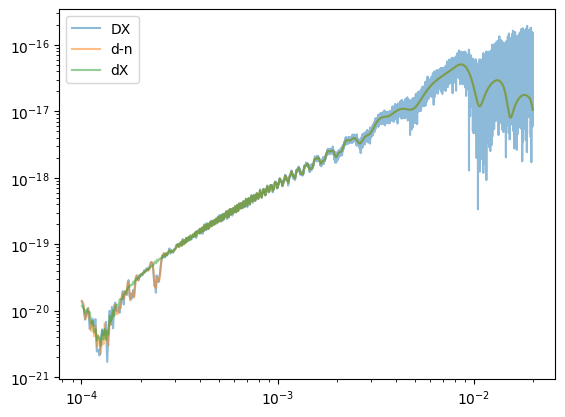

In [80]:
plt.loglog(fvec, np.abs(DX),alpha = 0.5, label = 'DX')
plt.loglog(fvec, np.abs(DX - X_ttl_unit*0.024),alpha = 0.5, label = 'd-n')
plt.loglog(fvec, np.abs(dX[snr_mask]),alpha = 0.5, label = 'dX')
plt.legend()


In [81]:
#likelihood stuff
def whip(a, b, Npsd):
    product = np.real(a)*np.real(b) + np.imag(a)*np.imag(b)
    arg = product*Npsd
    return arg

def XYZLikelihood_fast(pvector):
    #Build the waveform
    pvector = np.asarray(pvector).reshape(-1)          # (1, 12) -> (12,)
    src = {k: v for k, v in zip(keys, pvector[:11])}   # first 11 = C_ttlttl = pvector[11]    
    C_ttl = pvector[11] 

    tdisignal = lisa.GetCAmpPhaseTDI(lisa.GenerateLISATDI_SMBH(src, 
                                                gridfreq=fvec, 
                                                scale_freq_hm = False,
                                                **waveform_params_smbh))
    modesf = tdisignal['modes']

    df = fvec[1]-fvec[0]

    hA = np.zeros(len(fvec), dtype=complex)
    hE = np.zeros(len(fvec), dtype=complex)
    hT = np.zeros(len(fvec), dtype=complex)

    for i in range(len(modesf)):
        mbh_lb = tdisignal[modesf[i]]
        
        #phase
        splPh = mbh_lb['phase']
        #A
        splAr = mbh_lb['amp_real_chan1']
        splAi = mbh_lb['amp_imag_chan1']

        #E
        splEr = mbh_lb['amp_real_chan2']
        splEi = mbh_lb['amp_imag_chan2']

        #T
        splTr = mbh_lb['amp_real_chan3']
        splTi = mbh_lb['amp_imag_chan3']

        A_partial = np.conjugate((splAr + 1.j*splAi) * np.exp(1j*splPh))
        E_partial = np.conjugate((splEr + 1.j*splEi) * np.exp(1j*splPh))
        T_partial = np.conjugate((splTr + 1.j*splTi) * np.exp(1j*splPh))

        hA += A_partial
        hE += E_partial
        hT += T_partial

    hX, hY, hZ = AETtoXYZ(hA, hE, hT)

    #subtract ttl from data
    rX = DX - X_ttl_unit*C_ttl
    rY = DY - Y_ttl_unit*C_ttl
    rZ = DZ - Z_ttl_unit*C_ttl

    #where DX/Y/Z is data and hX/Y/Z is trial
    #<d|h>
    DXX = whip(rX, hX, diagn)
    DYY = whip(rY, hY, diagn)
    DZZ = whip(rZ, hZ, diagn)
    DXY = whip(rX, hY, offdiagn) + whip(rY, hX, offdiagn)
    DXZ = whip(rX, hZ, offdiagn) + whip(rZ, hX, offdiagn)
    DYZ = whip(rY, hZ, offdiagn) + whip(rZ, hY, offdiagn)

    #<h|h> terms
    hXX = whip(hX, hX, diagn)
    hYY = whip(hY, hY, diagn)
    hZZ = whip(hZ, hZ, diagn)
    hXY = 2*whip(hX, hY, offdiagn)
    hXZ = 2*whip(hX, hZ, offdiagn)
    hYZ = 2*whip(hY, hZ, offdiagn)

    #<d|d> terms
    rXX = whip(rX, rX, diagn)
    rYY = whip(rY, rY, diagn)
    rZZ = whip(rZ, rZ, diagn)
    rXY = 2*whip(rX, rY, offdiagn)
    rXZ = 2*whip(rX, rZ, offdiagn)
    rYZ = 2*whip(rY, rZ, offdiagn)


    loglik = 4*df*(np.sum([DXX, DYY, DZZ, DXY, DXZ, DYZ])-0.5*np.sum([hXX, hYY, hZZ, hXY, hXZ, hYZ])-0.5*np.sum([rXX, rYY, rZZ, rXY, rXZ, rYZ]))

    return loglik

In [82]:
#Priors
day_sec = 86400

priors = {"mbh": ProbDistContainer({
    0: uniform_dist(-np.pi/2, np.pi/2), #beta
    1: uniform_dist(-np.pi, np.pi), #lambda
    2: uniform_dist(-1, 1), #chi1
    3: uniform_dist(-1, 1), #chi2
    4: uniform_dist(1*day_sec, 10*day_sec),#(75*day_sec, 175*day_sec), #deltat
    5: uniform_dist(-np.pi, np.pi), #phi
    6: uniform_dist(500.0, 2000000.0), #dist 
    7: uniform_dist(0., np.pi), #psi
    8: uniform_dist(0., np.pi), #inc
    9: uniform_dist(1e4, 1e7), #mchirp 
    10: uniform_dist(1, 10), #q
    11: uniform_dist(0.0, 0.05) #one TTL parameter 0-10mm/rad
})}


ntemps = 8
nwalkers = 24
nsamples = 5000
ndims = {"mbh": 12}

theta0 = np.array([[np.hstack(
          (np.random.randn(ndims["mbh"]) * 1e-8) + np.array(list(src0.values()) + [0.024]))
          for i in range(nwalkers)]
          for _ in range(ntemps)])

start_state = State({"mbh": theta0})

import multiprocessing as mp

with mp.get_context("fork").Pool(8) as pool:
    sampler2 = EnsembleSampler(
        nwalkers,
        ndims,
        XYZLikelihood_fast,
        priors,
        pool = pool,
        args=(),
        branch_names=["mbh"],
        tempering_kwargs=dict(ntemps=ntemps),
        nleaves_max=dict(mbh=1),
    )
    sampler2.run_mcmc(start_state, nsamples, progress=True, store = True)

100%|██████████| 5000/5000 [4:40:26<00:00,  3.37s/it]  


# Run Sampler

# Outputs

In [83]:
#define truths
keys = src0.keys()
labels = list(keys) + ['C_12nRx']

inj=np.array(list(src0.values()) + [0.024])

truths = inj.flatten()
labels_final = labels

#Save Truths
truth = pd.DataFrame(data = truths , columns = ['truths'])
csv_filename_truth = save_name + "_truth_TTL_coeff.csv"
truth.to_csv(csv_filename_truth, index=False)

Chain data saved to XYZ_Original_source_1mm_fix_chains_fixed.csv


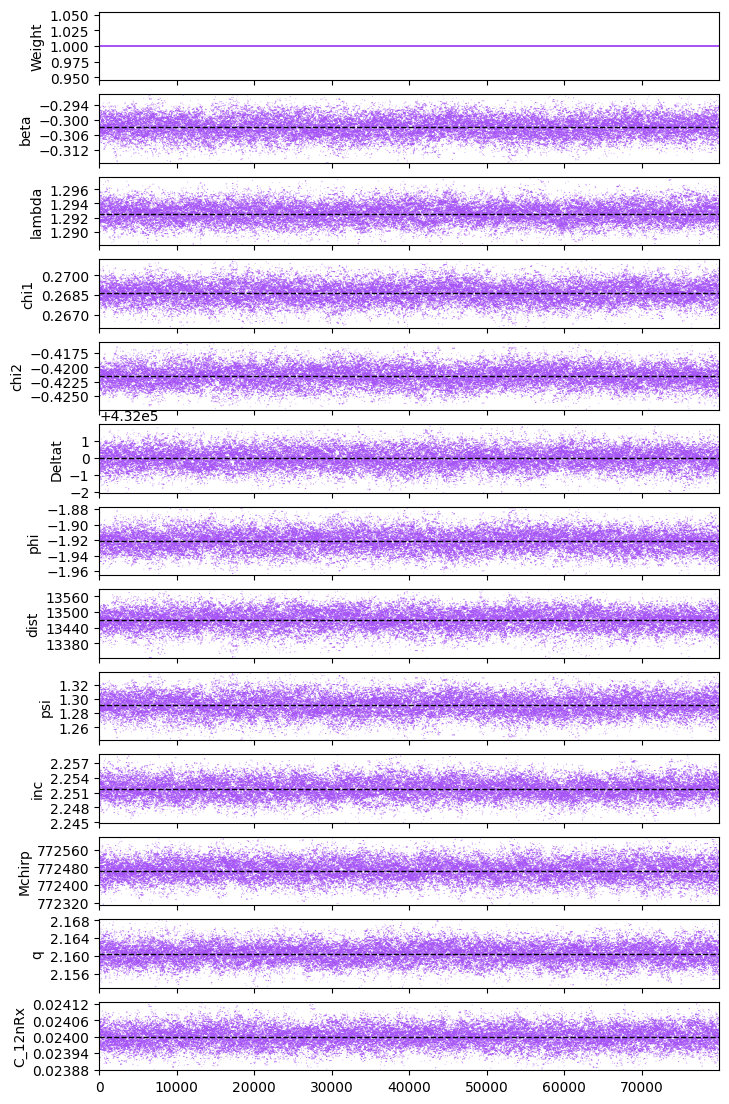

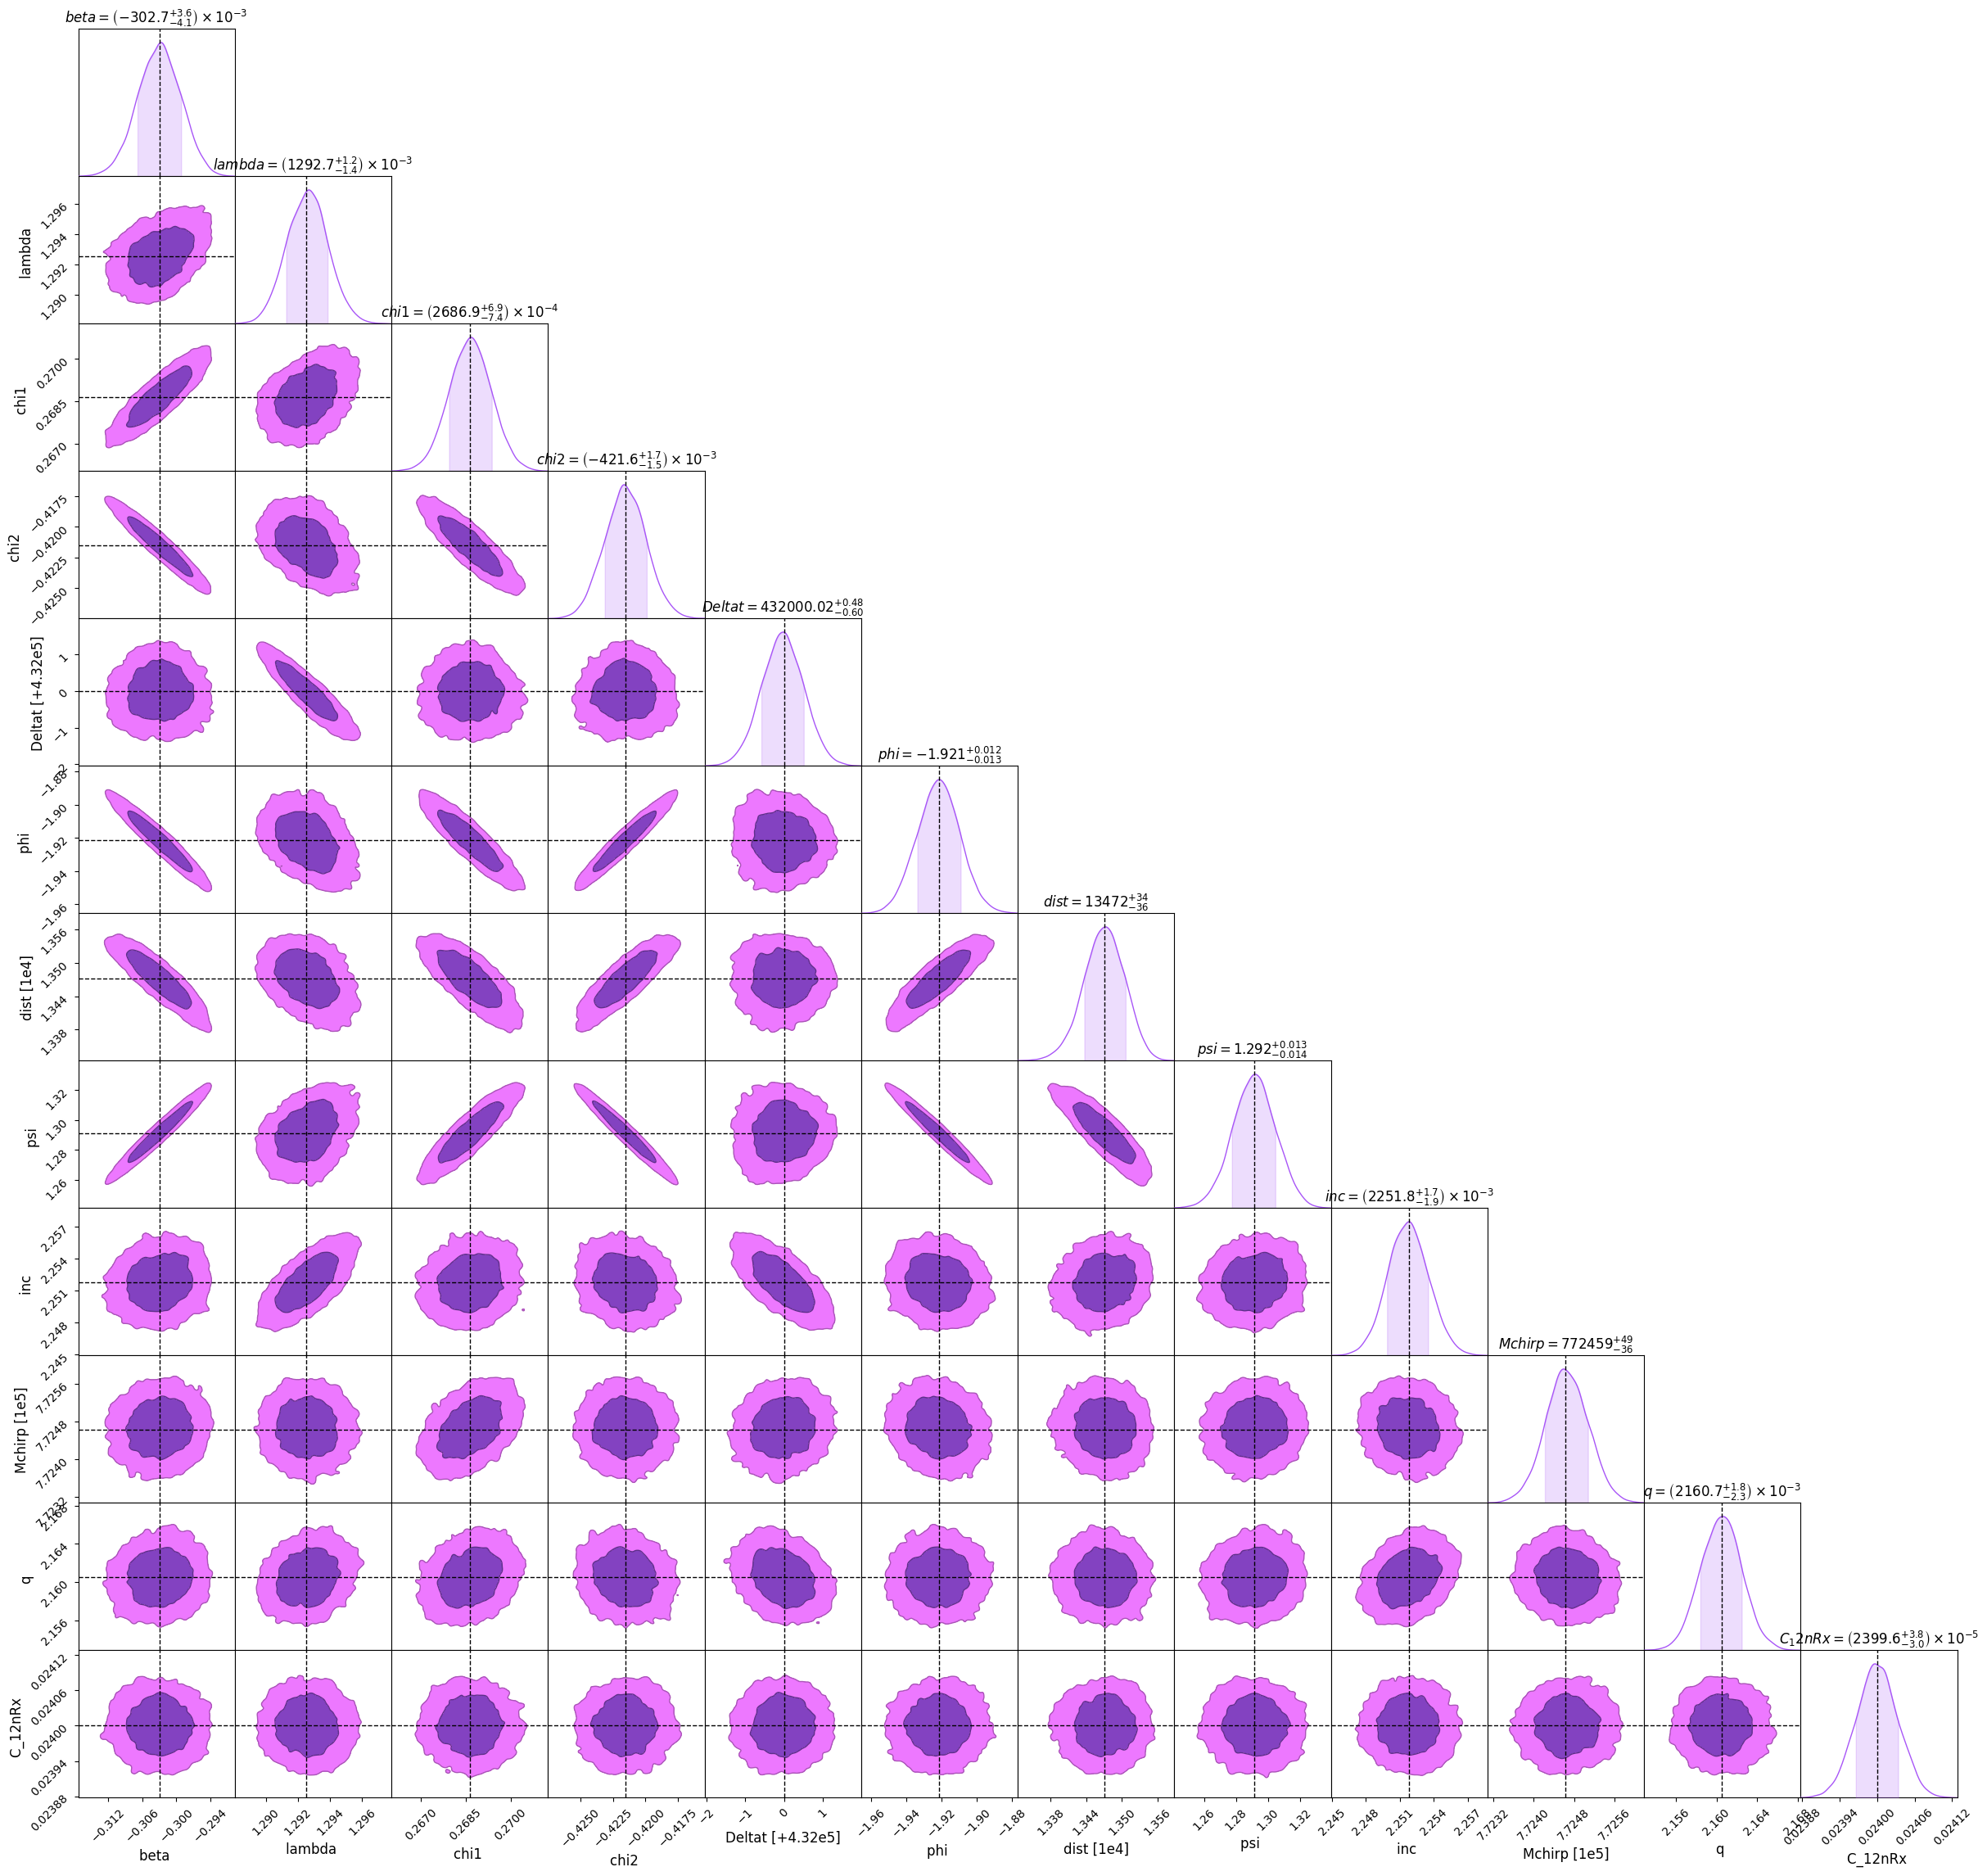

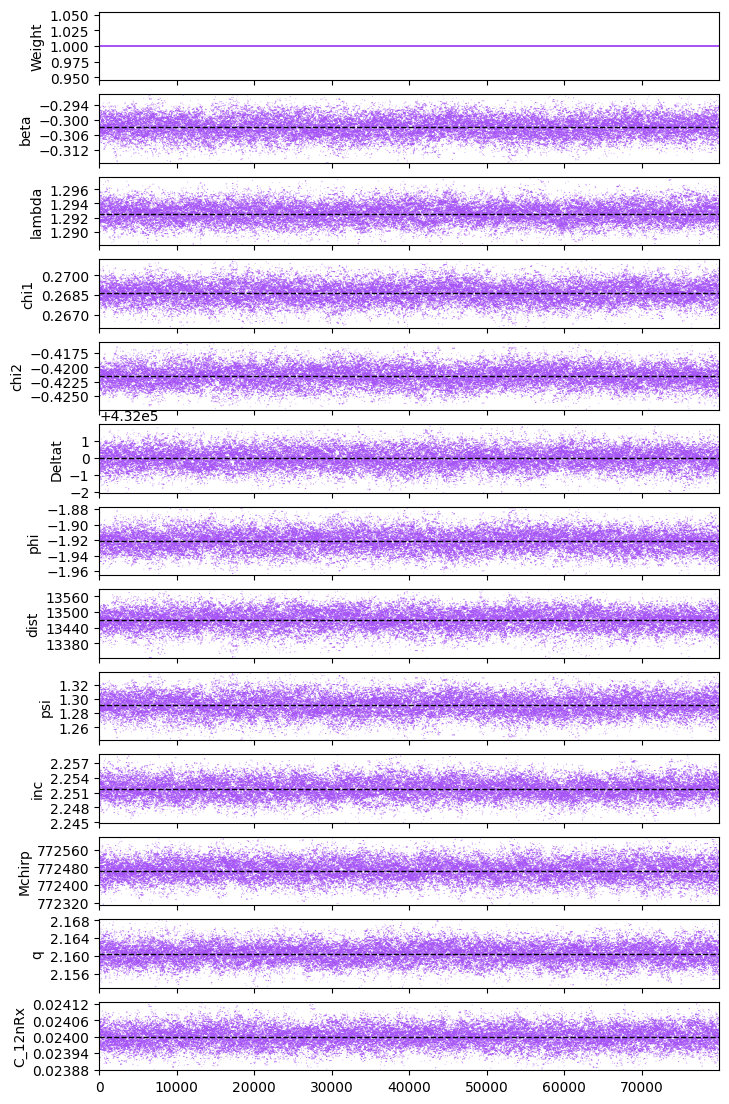

In [ ]:
a = ChainConsumer()
burn = 40000
one_samples = sampler2.get_chain()["mbh"][:, 0].reshape(-1, 12)

one_samp= pd.DataFrame(one_samples[burn:, :], columns = labels)

a.add_chain(Chain(samples=one_samp, name="1mm", color="purple"))
a.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

csv_filename_1mm = save_name + "_chains_fixed.csv"
#one_samp.to_csv(csv_filename_1mm, index=False)
print(f"Chain data saved to {csv_filename_1mm}")

a.plotter.plot()
a.plotter.plot_walks()

Full chain shape: (5000, 8, 24, 1, 12)
Coldest-chain shape used for plotting: (5000, 24, 12)


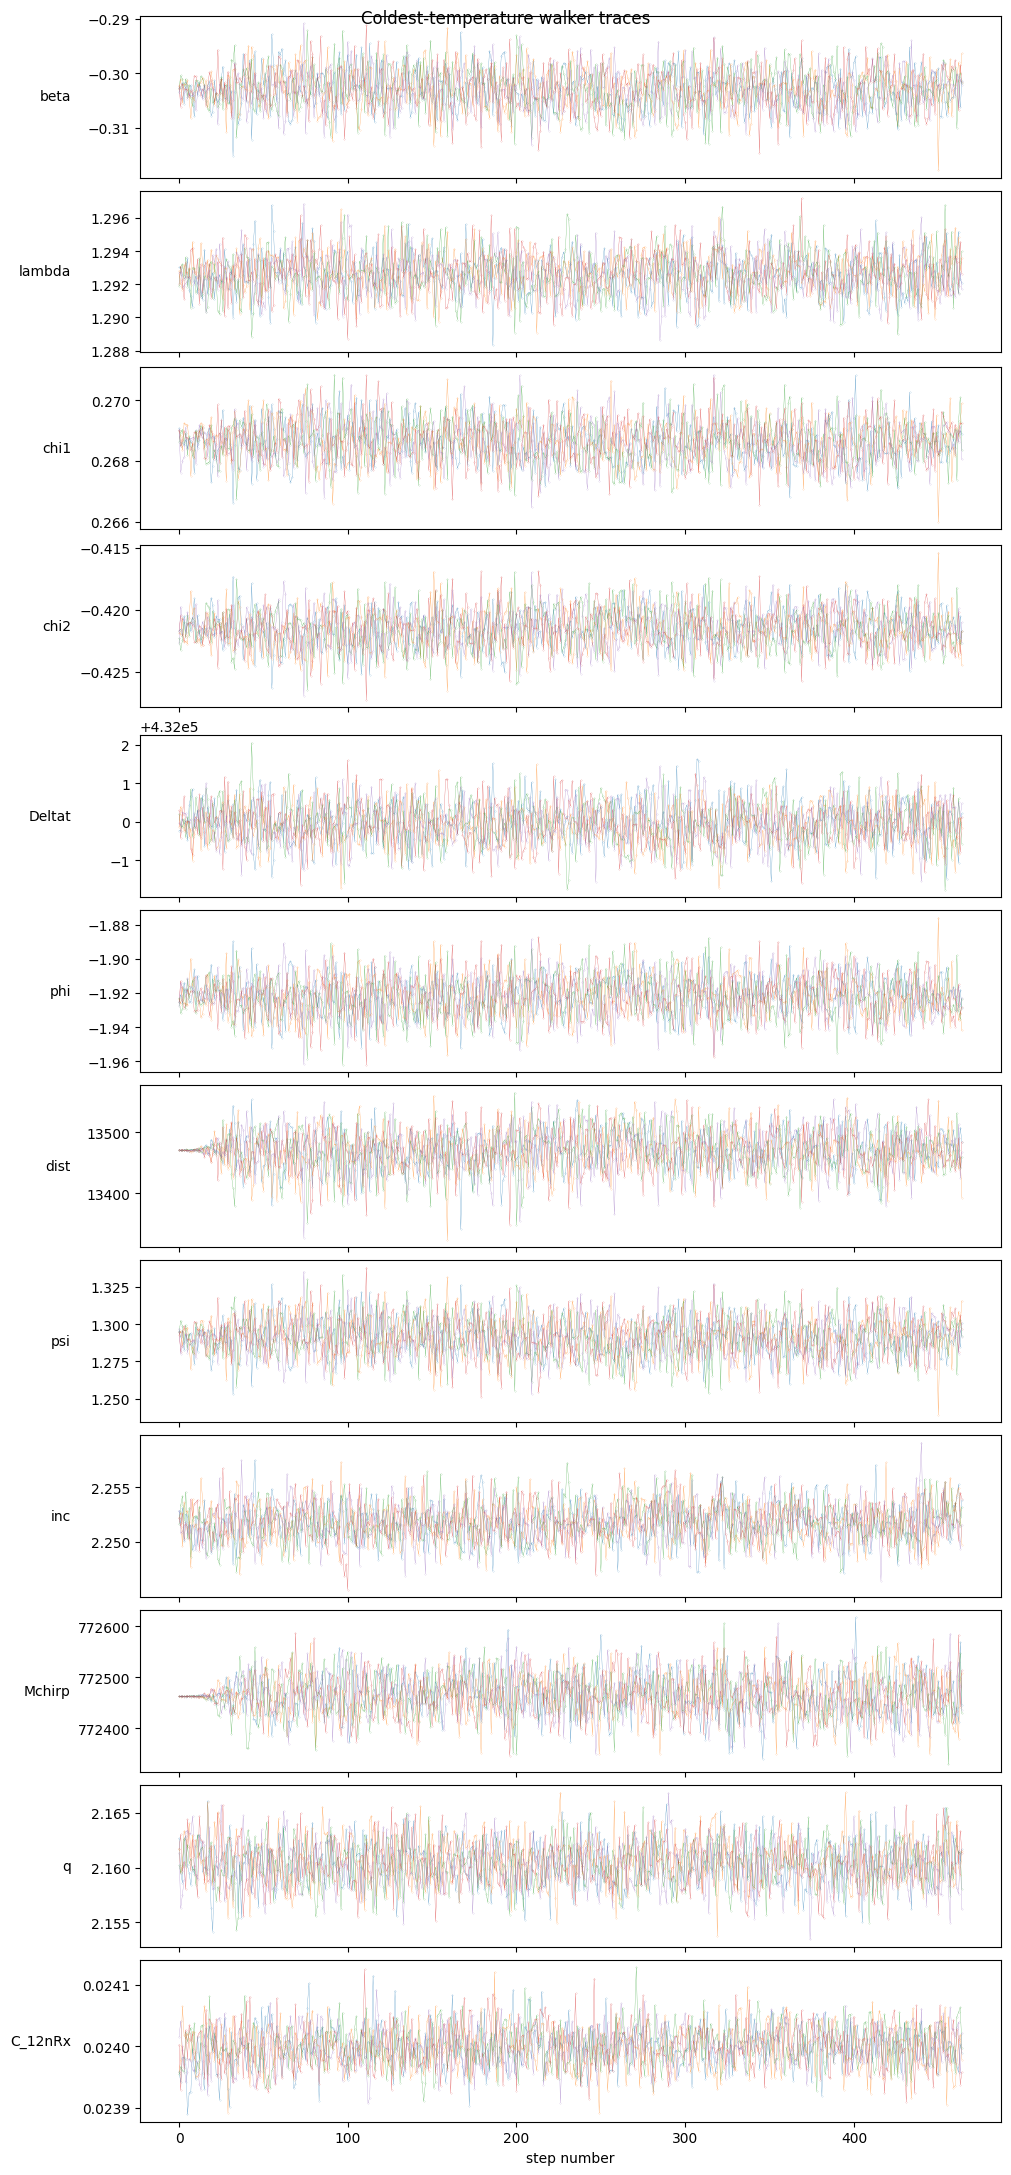

In [85]:
"""
Per-walker trace plots for the coldest temperature chain of an Eryn MCMC run.

Uses `sampler` (an already-run eryn.ensemble.EnsembleSampler) directly,
matching the ChainConsumer-based workflow. Does NOT reshape/flatten the
walker axis away, so each walker's trajectory stays distinguishable.
"""

import numpy as np
import matplotlib.pyplot as plt

# ---- 1. Get the full chain for the "mbh" branch ----------------------------
# shape: (nsteps, ntemps, nwalkers, nleaves_max, ndim)
full_chain = sampler2.get_chain()["mbh"]
#full_chain_pd = pd.DataFrame(full_chain)
print("Full chain shape:", full_chain.shape)

#csv_filename_0mm_full = "0mm_"+ save_name + "_fullchains.csv"
#full_chain_pd.to_csv(csv_filename_0mm_full, index=False)
#print(f"Chain data saved to {csv_filename_0mm_full}")

# ---- 2. Select coldest temperature (index 0 = beta=1) ----------------------
cold_chain = full_chain[:, 0]  # (nsteps, nwalkers, nleaves_max, ndim)

# Keep walkers separate. If nleaves_max == 1, just drop that axis.
# If you have multiple leaves and want each leaf's trace too, flatten
# (nwalkers, nleaves_max) together instead of picking leaf 0.
if cold_chain.shape[2] == 1:
    cold_chain = cold_chain[:, :, 0, :]        # -> (nsteps, nwalkers, ndim)
else:
    cold_chain = cold_chain[:, :, 0, :]        # or: .reshape(cold_chain.shape[0], -1, cold_chain.shape[-1])

nsteps, nwalkers, ndim = cold_chain.shape
print(f"Coldest-chain shape used for plotting: {cold_chain.shape}")

# ---- 3. Optional: discard burn-in / thin -----------------------------------
burn = 350      # e.g. 5000
thin = 1
cold_chain = cold_chain[burn::thin]
nsteps = cold_chain.shape[0]

# ---- 4. Plot trace plots ----------------------------------------------------
#labels = list(src0.keys()) 

# Map each walker index to a color along a colormap
cmap = plt.get_cmap("plasma")  # try "plasma", "turbo", "cool", etc.
colors = cmap(np.linspace(0, 2, nwalkers))

fig, axes = plt.subplots(ndim, 1, figsize=(10, 1.8 * ndim), sharex=True, constrained_layout = True)

for i in range(ndim):
    ax = axes[i]
    for w in range(0,5):#nwalkers):
        ax.plot(cold_chain[:, w, i][::10], alpha=0.8, marker = '.', markersize = 0.2, lw=0.2)#, color=colors[w])
    ax.set_ylabel(labels[i], rotation=0, ha="right", va="center")
    ax.yaxis.set_label_coords(-0.08, 0.5)

axes[-1].set_xlabel("step number")
fig.suptitle("Coldest-temperature walker traces", y=1.0)

# Add a colorbar showing walker index -> color mapping
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=nwalkers - 1))
sm.set_array([])
#cbar = fig.colorbar(sm, ax=axes, location="right", fraction=0.02, pad=0.02)
#cbar.set_label("walker index")

#plt.savefig(save_name+"plot.png", dpi=150, bbox_inches="tight")
plt.show()

Text(0.5, 1.0, 'X Channel MBHB TTL $C_{12\\eta Rx}$ Coefficient Correction')

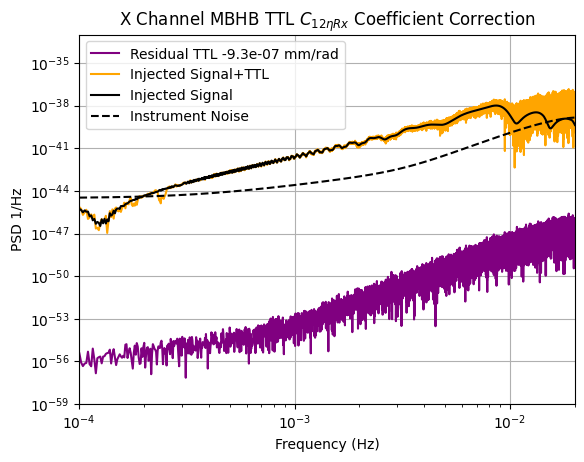

In [109]:
#plt.loglog(fvec_sim, 2 * np.abs(waveform_only_freq)**2/instru_duration, label = 'rfft(w*irfft h)')
res_ttl = (0.024-np.mean(one_samp['C_12nRx'][burn:]))
plt.loglog(fvec, 2 * np.abs(X_ttl_unit*res_ttl)**2/ instru_duration, color = 'purple', label = 'Residual TTL {0:.1e} mm/rad'.format(res_ttl)) #point estimate residual noise
plt.loglog(fvec, 2 * np.abs(DX)**2/ instru_duration, color = 'orange', label = 'Injected Signal+TTL')#(signal + noise) injection
plt.loglog(fvec, 2 * np.abs(dX[snr_mask])**2/ instru_duration, color = 'black', label = 'Injected Signal') # signal injection
plt.loglog(fvec, np.abs(Npsd_X[snr_mask]), linestyle = '--', color = 'black', label = 'Instrument Noise') #Npsd_X
plt.ylim([10e-60, 10e-34])
plt.xlim([1e-4, 2e-2])
plt.grid()
plt.xlabel('Frequency (Hz)')
plt.ylabel("PSD 1/Hz")

plt.legend()
plt.title(r"X Channel MBHB TTL $C_{12\eta Rx}$ Coefficient Correction")